# Antidiabétiques en France : analyse en SQL et consommation par habitant (Open Medic 2024)

**Question :** quels antidiabétiques sont remboursés en France, qui les prescrit, et **quelles régions en consomment le plus par habitant** ?

**Données :**
- Open Medic 2024 (Assurance maladie, extrait du SNDS), classe ATC A10 « Médicaments du diabète ». Source : [ameli.fr](https://www.assurance-maladie.ameli.fr/etudes-et-donnees/open-medic-base-complete-depenses-medicaments) · Licence Ouverte Etalab.
- Populations régionales au 1er janvier 2024 : [INSEE, estimations de population](https://www.insee.fr/fr/statistiques/7752095).

**Méthode :** les données sont chargées dans une base SQLite (3 tables) et analysées en **SQL** (`GROUP BY`, `CASE WHEN`, `HAVING`, sous-requêtes, `JOIN`). Les résultats R1 à R4 sont **vérifiés** en les comparant à l'analyse pandas du [premier notebook](openmedic_antidiabetiques_2024.ipynb).

**Auteure :** Linda MISLANGE MEGOUKENG TEGIEU

## 1. Chargement du fichier Open Medic 2024

In [1]:
from google.colab import files
import zipfile, os, shutil

envoi = files.upload()
nom = list(envoi)[0]
os.makedirs("openmedic_2024", exist_ok=True)
if zipfile.is_zipfile(nom):
    zipfile.ZipFile(nom).extractall("openmedic_2024")
else:
    shutil.move(nom, os.path.join("openmedic_2024", nom))
print("Fichiers :", os.listdir("openmedic_2024"))

Saving OPEN_MEDIC_2024.zip to OPEN_MEDIC_2024.zip
Fichiers : ['OPEN_MEDIC_2024.CSV']


## 2. Création de la base SQL

Filtrage de la classe A10 (lecture par morceaux), conversion des montants au format français, puis création de la table `openmedic`.

In [14]:
import glob, sqlite3
import pandas as pd

fichier = max([f for f in glob.glob("openmedic_2024/**/*", recursive=True) if os.path.isfile(f)], key=os.path.getsize)

morceaux = []
for morceau in pd.read_csv(fichier, sep=";", encoding="latin-1", chunksize=500_000, dtype=str):
    morceaux.append(morceau[morceau["ATC2"] == "A10"])
a10 = pd.concat(morceaux, ignore_index=True)

def en_nombre(colonne):
    return pd.to_numeric(colonne.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
a10["BOITES"] = en_nombre(a10["BOITES"])
a10["REM"] = en_nombre(a10["REM"])

# Table 1 : openmedic (les colonnes utiles seulement)
con = sqlite3.connect(":memory:")
colonnes = ["ATC3", "L_ATC3", "ATC5", "L_ATC5", "age", "sexe", "BEN_REG", "PSP_SPE", "BOITES", "REM"]
a10[colonnes].to_sql("openmedic", con, index=False)

def sql(requete):
    return pd.read_sql(requete, con)

print("Lignes chargées :", sql("SELECT COUNT(*) AS n FROM openmedic")["n"][0])

Lignes chargées : 66390


### Table `prescripteurs`
Correspondance entre les codes de spécialité et leur libellé.

In [15]:
prescripteurs = pd.DataFrame({
    "PSP_SPE": ["1", "42", "90"],
    "specialite": ["Médecine générale libérale", "Endocrinologie libérale", "Prescripteurs salariés"],
})
prescripteurs.to_sql("prescripteurs", con, index=False)
sql("SELECT * FROM prescripteurs")

,PSP_SPE,specialite
0,1,Médecine générale libérale
1,42,Endocrinologie libérale
2,90,Prescripteurs salariés


### Table `regions`
Population totale au 1er janvier 2024 (INSEE). Pour correspondre aux regroupements d'Open Medic, le code 93 additionne Provence-Alpes-Côte d'Azur et la Corse, et le code 5 les cinq départements et régions d'outre-mer (Guadeloupe, Martinique, Guyane, La Réunion, Mayotte).

In [16]:
regions = pd.DataFrame({
    "BEN_REG": ["11", "24", "27", "28", "32", "44", "52", "53", "75", "76", "84", "93", "5"],
    "region": ["Île-de-France", "Centre-Val de Loire", "Bourgogne-Franche-Comté", "Normandie",
               "Hauts-de-France", "Grand Est", "Pays de la Loire", "Bretagne", "Nouvelle-Aquitaine",
               "Occitanie", "Auvergne-Rhône-Alpes", "PACA et Corse", "Outre-mer"],
    "population": [
        12419961,  # Île-de-France
        2573295,  # Centre-Val de Loire
        2791719,  # Bourgogne-Franche-Comté
        3327077,  # Normandie
        5983823,  # Hauts-de-France
        5568711,  # Grand Est
        3926389,  # Pays de la Loire
        3453023,  # Bretagne
        6154772,  # Nouvelle-Aquitaine
        6154729,  # Occitanie
        8235923,  # Auvergne-Rhône-Alpes
        5553539,  # PACA + Corse
        2230472,  # Outre-mer (5 DROM)
    ],
})

# Vérification
manquants = regions["population"].isna().sum()
if manquants:
    print(f"⚠️ Il manque encore {manquants} population(s).")
else:
    total = regions["population"].sum() / 1e6
    print(f"Population totale : {total:.1f} millions")
    print("✅ Ordre de grandeur correct" if 67 < total < 70 else "❌ Le total devrait être autour de 68 millions : vérifie tes chiffres.")
    regions.to_sql("regions", con, index=False, if_exists="replace")

Population totale : 68.4 millions
✅ Ordre de grandeur correct


---
## 3. Résultats du projet 1, recalculés en SQL

Chaque résultat est comparé à celui obtenu avec pandas : deux méthodes, mêmes chiffres.

### R1. Volume total
**Vérification :** identique au projet 1 (84 millions de boîtes, 1 846,2 M€).

In [17]:
sql("""
SELECT ROUND(SUM(BOITES) / 1e6, 1) AS boites, ROUND(SUM(REM) / 1e6, 1) AS euros
FROM openmedic
""")

,boites,euros
0,84.0,1846.2


### Calcul de parts avec une sous-requête
La sous-requête `(SELECT SUM(BOITES) FROM openmedic)` calcule le total général, qui sert de dénominateur pour chaque groupe. Exemple par sexe (1 = homme, 2 = femme, 9 = inconnu) :

In [18]:
sql("""
SELECT sexe,
       SUM(BOITES) AS boites,
       ROUND(100.0 * SUM(BOITES) / (SELECT SUM(BOITES) FROM openmedic), 1) AS part_pct
FROM openmedic
GROUP BY sexe
""")

,sexe,boites,part_pct
0,1,47632114,56.7
1,2,36365359,43.3
2,9,6009,0.0


### R2. Répartition par tranche d'âge
**Vérification :** identique au projet 1 (60 ans et plus : 73,9 %).

In [19]:
sql("""
SELECT CASE WHEN age = '0' THEN '0-19 ans'
            WHEN age = '20' THEN '20-59 ans'
            WHEN age = '60' THEN '60 ans et +'
            ELSE 'Inconnu' END AS tranche,
       SUM(BOITES) AS boites,
       ROUND(100.0 * SUM(BOITES) / (SELECT SUM(BOITES) FROM openmedic), 1) AS part_pct
FROM openmedic
GROUP BY tranche
""")

,tranche,boites,part_pct
0,0-19 ans,915678,1.1
1,20-59 ans,20974131,25.0
2,60 ans et +,62044356,73.9
3,Inconnu,69317,0.1


### R3. Top 10 des molécules en nombre de boîtes
**Vérification :** identique au projet 1 (metformine : 29 026 361 boîtes, 34,6 %).

In [20]:
sql("""
SELECT ATC5, L_ATC5, SUM(BOITES) AS boites,
       ROUND(100.0 * SUM(BOITES) / (SELECT SUM(BOITES) FROM openmedic), 1) AS part_pct
FROM openmedic
GROUP BY ATC5, L_ATC5
ORDER BY boites DESC
LIMIT 10
""")

,ATC5,L_ATC5,boites,part_pct
0,A10BA02,METFORMINE,29026361,34.6
1,A10BK01,DAPAGLIFLOZINE,8062303,9.6
2,A10BB09,GLICLAZIDE,6145984,7.3
3,A10AE04,INSULINE GLARGINE,4912300,5.8
4,A10AB05,INSULINE ASPART,4433975,5.3
5,A10BD07,METFORMINE ET SITAGLIPTINE,4416587,5.3
6,A10BH01,SITAGLIPTINE,4005947,4.8
7,A10BJ06,SEMAGLUTIDE,3642446,4.3
8,A10BJ05,DULAGLUTIDE,3402352,4.1
9,A10BK03,EMPAGLIFLOZINE,2508521,3.0


### R4. Top 10 des molécules en montant remboursé
**Vérification :** identique au projet 1 (dapagliflozine : 303,2 M€, 37,61 € par boîte).

*Point d'attention :* le regroupement se fait par **code** ATC5 et non par nom. Plusieurs codes portent le même nom (par exemple l'insuline aspart rapide et en mélange) : grouper par nom les additionnait et faussait les montants. C'est la comparaison avec le projet 1 qui a révélé l'écart.

In [40]:
sql("""
SELECT L_ATC5, ROUND(SUM(REM) / 1e6, 1) AS euros, SUM(BOITES) AS boites,
       ROUND(SUM(REM) / SUM(BOITES), 2) AS cout_moyen
FROM openmedic
GROUP BY ATC5, L_ATC5
ORDER BY euros DESC
LIMIT 10
""")

,L_ATC5,euros,boites,cout_moyen
0,DAPAGLIFLOZINE,303.2,8062303,37.61
1,DULAGLUTIDE,272.4,3402352,80.07
2,SEMAGLUTIDE,271.1,3642446,74.42
3,INSULINE GLARGINE,187.2,4912300,38.11
4,METFORMINE,99.2,29026361,3.42
5,INSULINE ASPART,98.0,4433975,22.11
6,EMPAGLIFLOZINE,94.3,2508521,37.57
7,INSULINE DEGLUDEC ET LIRAGLUTIDE,81.0,450710,179.71
8,INSULINE DEGLUDEC,68.6,1184957,57.92
9,INSULINE LISPRO,55.5,1909382,29.06


---
## 4. Analyses complémentaires

### R5. Insulines ou autres antidiabétiques ?
Classe ATC3 : A10A = insulines et analogues, A10B = autres hypoglycémiants.

In [46]:
sql("""
SELECT ATC3, L_ATC3, SUM(BOITES) AS boites, ROUND(SUM(REM) / 1e6, 1) AS euros, ROUND(100.0 * SUM(BOITES) / (SELECT SUM(BOITES) FROM openmedic), 1) AS part_boites,
       ROUND(100.0 * SUM(REM) / (SELECT SUM(REM) FROM openmedic), 1) AS part_euros, ROUND(SUM(REM) / SUM(BOITES), 2) AS cout_moyen
FROM openmedic
GROUP BY ATC3, L_ATC3
ORDER BY boites DESC
""")

,ATC3,L_ATC3,boites,euros,part_boites,part_euros,cout_moyen
0,A10B,"MEDICAMENTS HYPOGLYCEMIANTS, INSULINES EXCLUSES",69914054,1313.4,83.2,71.1,18.79
1,A10A,INSULINES ET ANALOGUES,14089428,532.8,16.8,28.9,37.82


**Réponse :** Les insulines représentent 16,8 % des boîtes mais 28,9 % des dépenses, car une boîte d'insuline coûte en moyenne deux fois plus cher (37,8 € contre 18,8 €).

### R6. Molécules chères et très utilisées
Molécules à plus de 50 € par boîte **et** plus de 100 000 boîtes remboursées.

In [41]:
sql("""
SELECT L_ATC5, SUM(BOITES) AS boites, ROUND(SUM(REM) / SUM(BOITES), 2) AS cout_moyen, ROUND(SUM(REM) / 1e6, 1) AS euros
FROM openmedic
GROUP BY ATC5, L_ATC5
HAVING SUM(REM) / SUM(BOITES) > 50 AND SUM(BOITES) > 100000
ORDER BY euros DESC
""")

,L_ATC5,boites,cout_moyen,euros
0,DULAGLUTIDE,3402352,80.07,272.4
1,SEMAGLUTIDE,3642446,74.42,271.1
2,INSULINE DEGLUDEC ET LIRAGLUTIDE,450710,179.71,81.0
3,INSULINE DEGLUDEC,1184957,57.92,68.6
4,LIRAGLUTIDE,428511,87.96,37.7


**Réponse :** Cinq molécules remplissent ces deux conditions : trois analogues du GLP-1 (dulaglutide, sémaglutide, liraglutide) et deux insulines récentes. À elles seules, elles représentent 730,8 M€, soit environ 40 % des dépenses d'antidiabétiques. La plus chère par boîte est l'association insuline dégludec + liraglutide (179,71 €).

### R7. Qui prescrit ? (JOIN avec la table `prescripteurs`)
**Vérification :** identique au projet 1 (médecine générale libérale : 76,3 %).

In [42]:
sql("""
SELECT specialite, SUM(BOITES) AS boites, ROUND(100.0 * SUM(BOITES) / (SELECT SUM(BOITES) FROM openmedic), 1) AS part_pct
FROM openmedic
JOIN prescripteurs ON openmedic.PSP_SPE = prescripteurs.PSP_SPE
GROUP BY specialite
""")

,specialite,boites,part_pct
0,Endocrinologie libérale,4460184,5.3
1,Médecine générale libérale,64068930,76.3
2,Prescripteurs salariés,13165521,15.7


**Note :** les autres spécialités n'apparaissent pas car leurs codes n'existent pas dans la table `prescripteurs` : un `JOIN` ne garde que les lignes qui ont une correspondance. Un `LEFT JOIN` (avec `openmedic` à gauche) les garderait, avec une spécialité vide (NULL).

---
## 5. Consommation par habitant

### R8. Boîtes pour 1 000 habitants, par région (JOIN avec la table `regions`)
Les boîtes sont d'abord additionnées par région, puis divisées par la population.

In [43]:
par_region = sql("""
SELECT region, SUM(BOITES) AS boites, population, ROUND(1000.0 * SUM(BOITES) / population, 0) AS boites_par_1000
FROM openmedic
JOIN regions ON openmedic.BEN_REG = regions.BEN_REG
GROUP BY region, population
ORDER BY boites_par_1000 DESC
""")
par_region

,region,boites,population,boites_par_1000
0,Outre-mer,3943552,2230472,1768.0
1,Hauts-de-France,8453459,5983823,1413.0
2,Bourgogne-Franche-Comté,3879357,2791719,1390.0
3,PACA et Corse,7720902,5553539,1390.0
4,Centre-Val de Loire,3510057,2573295,1364.0
5,Grand Est,7541559,5568711,1354.0
6,Normandie,4184567,3327077,1258.0
7,Nouvelle-Aquitaine,7621740,6154772,1238.0
8,Occitanie,7617840,6154729,1238.0
9,Auvergne-Rhône-Alpes,9243829,8235923,1122.0


Moyenne nationale : environ **1 226 boîtes pour 1 000 habitants** (total des boîtes divisé par la population totale).

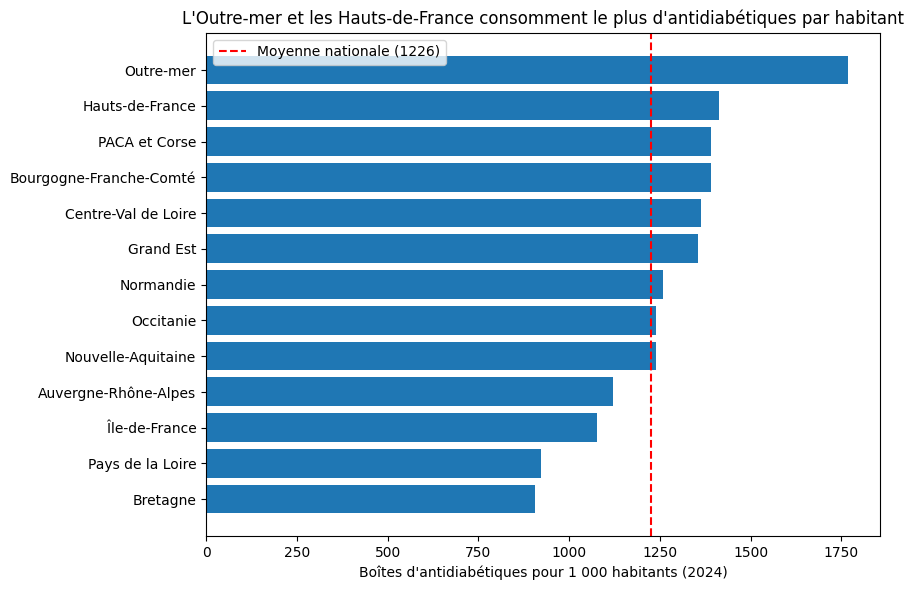

In [50]:
import matplotlib.pyplot as plt

moyenne = 1000 * par_region["boites"].sum() / par_region["population"].sum()   # moyenne nationale

donnees = par_region.sort_values("boites_par_1000")       # du plus petit au plus grand
plt.figure(figsize=(9, 6))
plt.barh(donnees["region"], donnees["boites_par_1000"])
plt.axvline(moyenne, color="red", linestyle="--", label=f"Moyenne nationale ({moyenne:.0f})")
plt.title("L'Outre-mer et les Hauts-de-France consomment le plus d'antidiabétiques par habitant")
plt.xlabel("Boîtes d'antidiabétiques pour 1 000 habitants (2024)")
plt.legend()
plt.tight_layout()
plt.show()

**Réponse :** L'Île-de-France passe de la 1re place en nombre brut à la 11e place par habitant. Elle avait beaucoup de boîtes simplement parce qu'elle a beaucoup d'habitants. L'Outre-mer (1 768 boîtes pour 1 000 habitants) et les Hauts-de-France (1 413) arrivent en tête. C'est cohérent avec ce qu'on sait du diabète en France, plus fréquent dans ces territoires. La Bretagne et les Pays de la Loire sont les plus bas.

**Limite :** Comme 74 % des boîtes sont destinées aux personnes de 60 ans et plus, les régions où la population est plus âgée en consomment davantage, même si le diabète n’y est pas plus fréquent. À l’inverse, l’Île-de-France, dont la population est plus jeune que la moyenne, se retrouve en partie avec un rang plus faible.

---
## 6. Conclusions

1. Les résultats du projet 1 (pandas) sont retrouvés à l'identique en SQL : 84 millions de boîtes et 1 846,2 M€ remboursés en 2024.
2. Les insulines représentent 16,8 % des boîtes mais 28,9 % des dépenses (37,8 € la boîte contre 18,8 € pour les autres antidiabétiques).
3. Cinq molécules récentes (trois GLP-1 et deux insulines) coûtent plus de 50 € la boîte et concentrent environ 40 % des dépenses.
4. **Par habitant**, le classement des régions change complètement : l'Outre-mer (1 768 boîtes pour 1 000 habitants) et les Hauts-de-France (1 413) arrivent en tête, l'Île-de-France passe de la 1re à la 11e place (1 077), la Bretagne (907) et les Pays de la Loire (923) sont les plus bas.

## Limites
- Les taux par habitant ne sont **pas standardisés sur l'âge** : une région plus âgée consomme mécaniquement plus.
- Open Medic compte des boîtes, pas des patients, et ne couvre que la pharmacie de ville.
- Les boîtes dont la région est inconnue (code 99, environ 0,2 %) sont exclues du calcul par habitant.

## Piste d'amélioration
Standardiser les taux par âge à partir des populations INSEE par tranche d'âge.